# kMC 3D: difusión superficial, visualización y calibración de β-hematina

Segundo notebook del motor 3D (`3DkMC/kmc3d`; plan en `3DkMC/PLAN_3DkMC.md`). Continúa
el notebook 01 con tres cosas:

1. **Difusión superficial** (Fase 4): saltos de una unidad de superficie a un sitio
   vacío cercano, con balance detallado.
2. **Visualización del cristal 3D**: superficie coloreada por faceta, poliedros de
   Wulff, proyecciones de espesor tipo TEM y animación por facetas (todo con
   matplotlib, sin WebGL).
3. **Un pendiente de β-hematina: la calibración F3** de las energías de enlace
   efectivas con la morfología observada, usando el kMC y no solo la teoría de energía
   de unión, con varias semillas del RNG.

| § | Contenido |
|---|---|
| 0 | Revisión de pendientes |
| 1 | Configuración |
| 2 | Difusión superficial: tasas, Kossel, relajación de una varilla |
| 3 | Visualizaciones nuevas |
| 4 | Calibración de β-hematina con la morfología |
| 5 | Conclusiones y pendientes que quedan |

**Unidades.** Energías en kT; Δμ/kT = ln(1 + σ); tiempo en 1/k0 (k0 = 1); distancias en
unidades de celda (Kossel) o en Å (β-hematina).

**Aviso.** Las energías de β-hematina de este notebook, incluidas las calibradas en §4,
son **efectivas y provisionales**: salen de ajustar una forma, no de un campo de fuerzas
ni de datos cinéticos. No deben citarse como energías de enlace reales.

## 0. Revisión de pendientes

Estado de los pendientes de `PLAN_3DkMC.md` (§6 y §8) antes de este notebook y qué se
hace aquí:

| Pendiente | Antes | En este notebook |
|---|---|---|
| F2: modo *slab* (caja periódica por cara) | pendiente | sigue pendiente |
| F3.1: origen de las energías (D3) | provisionales, elegidas con E_att | **ajuste (b) a la morfología con el kMC** (§4) |
| F3.2: Δμ y k0 con datos experimentales (AFM de (100)) | pendiente | sigue pendiente: necesita datos experimentales |
| F3.3: criterios de morfología | enunciados | **6 criterios medibles** (`kmc3d/calibration.py`) |
| F3.4: barridos con varias semillas | pendiente | **hecho**: rejilla, 5 semillas y un tamaño mayor |
| F4: difusión superficial | pendiente | **hecho** (§2) |
| F4: reservorio finito, aditivos, tasas adaptativas 3D | pendiente | siguen pendientes |
| F5: réplicas en paralelo | pendiente | **hecho** con `subprocess` (`kmc3d/parallel.py`) |
| F5: compilación del bucle | pendiente | pendiente (numba necesita el visto bueno del autor) |
| F6: base > 1, grafo desde CIF | pendiente | pendiente |
| Visualización | vóxeles y proyecciones de puntos (moiré) | **render por facetas, Wulff, espesores y animación** (§3) |

De los pendientes propios de β-hematina (F3.1–F3.4) se elige la **calibración con la
morfología** (F3.1 opción (b), con F3.3 y F3.4). Es el único que no necesita datos
nuevos. La parte cinética (F3.2, k0 y Δμ con AFM) queda fuera.

## 1. Configuración

In [1]:
import pickle
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display
from matplotlib.colors import LinearSegmentedColormap

# Raíz de 3DkMC: la carpeta que contiene kmc3d/ (funciona desde notebooks/ o desde 3DkMC/)
ROOT_3D = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "kmc3d").is_dir())
sys.path.insert(0, str(ROOT_3D))

from kmc3d import KMC3D, SplitRates, presets, seeds                         # noqa: E402
from kmc3d import analysis as an, calibration as cal, render, viz           # noqa: E402
from kmc3d.geometry import hkl_label, parse_hkl                             # noqa: E402
from kmc3d.parallel import run_parallel                                     # noqa: E402
from kmc3d.rates import SurfaceDiffusion                                    # noqa: E402

# Figuras, tablas y caché de las corridas pesadas
OUT = ROOT_3D / "outputs" / "02_difusion_visualizacion_calibracion"
CACHE = OUT / "cache"
GUARDAR = True
CACHE.mkdir(parents=True, exist_ok=True)


def guardar(fig, nombre):
    # Guarda la figura en OUT si GUARDAR = True
    if GUARDAR:
        fig.savefig(OUT / f"{nombre}.png", dpi=150, bbox_inches="tight")


def en_cache(nombre, calcular):
    # Devuelve el resultado guardado en CACHE/<nombre>.pkl o lo calcula y lo guarda.
    # Borra el archivo para recalcular.
    f = CACHE / f"{nombre}.pkl"
    if f.exists():
        with open(f, "rb") as fh:
            return pickle.load(fh)
    t0 = time.perf_counter()
    r = calcular()
    with open(f, "wb") as fh:
        pickle.dump(r, fh)
    print(f"{nombre}: calculado en {time.perf_counter() - t0:.0f} s")
    return r


# Paleta categórica fija (orden estable, nunca cíclica), marcadores y rampa secuencial
COLORES = render.FACE_PALETTE
MARCAS = viz.MARKERS
AZULES = LinearSegmentedColormap.from_list("azules", render.SEQ_BLUES)
# Divergente: dos tonos con un gris neutro en el centro
DIVERGENTE = LinearSegmentedColormap.from_list("div", ["#eb6834", "#f1f0ec", "#2a78d6"])
FACES = cal.FACES          # (100), (010), (001), (011), (01-1), (110), (1-10), (101), (10-1)
pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})
T0_NOTEBOOK = time.perf_counter()

## 2. Difusión superficial

### 2.1 Tasas

Una unidad ocupada de superficie en el sitio i (energía de enlace E_i = Σ φ de sus
vecinos ocupados) salta a un sitio vacío f = i + δ con tasa

  k(i → f) = k_d · w_δ · exp[−(E_i − E_kink)],   E_kink = Σφ,

es decir, la barrera es la energía de enlace del origen (Arrhenius, como en
Gilmer-Bennema 1972). Al hacer el salto, la unidad pierde los enlaces de i y gana los de
f, y la energía de enlace en el destino (sin contar el enlace con el origen) es E_f. Así

  k(i → f) / k(f → i) = exp(E_f − E_i)

y se cumple el **balance detallado** respecto de la energía de enlace (comprobado por
enumeración en `tests/test_diffusion.py`). Como N no cambia, Δμ no interviene.

**Reglas** (`kmc3d.rates.SurfaceDiffusion`, `kmc3d.engine`):
- Clases de eventos por código de vecindad del origen, como las de unión y despegue
  (algoritmo BKL sin cambios).
- El destino se elige dentro de la clase. Si no es válido, el evento se **rechaza**
  (paso nulo, exacto por *thinning* de Poisson). No es válido si está ocupado, si no
  tiene otro vecino ocupado (la unidad se iría a la solución: eso es un despegue), si
  cerraría un hueco con `allow_enclosed=False` o si cruza una diagonal ocupada.
- **Vectores de salto:** `"bonds"` (los vectores de enlace, por defecto), `"cube18"`
  (añade las diagonales de cara de la celda) o `"cube26"` (también las de cubo).
- **Sin difusión (k_d = 0), las trayectorias son idénticas bit a bit a las de antes**:
  el consumo del RNG no cambia (test `TestNoDiffusionUnchanged`).

Escala de k_d: con tasas de Gilmer, k_d/k0 compara el salto con el despegue desde el
mismo sitio (los dos con exp[−(E − E_kink)]). Con tasas simétricas el despegue solo
lleva la mitad del exponente, así que el cociente depende de E: lo calculo en §4.7.

In [2]:
# Tasas de salto y de despegue según el número de vecinos, en Kossel φ = 2
g_k = presets.kossel(2.0)
dif = SurfaceDiffusion(g_k, 1.0, hop_vectors="bonds")
gil = SplitRates.gilmer(g_k, 0.5)
# código de vecindad: n_t vecinos ocupados del tipo t (x, y, z), código = Σ n_t·3^t
filas = []
for n, cuenta in enumerate([(1, 0, 0), (1, 1, 0), (1, 1, 1), (2, 1, 1), (2, 2, 1)], start=1):
    code_n = sum(c * 3 ** t for t, c in enumerate(cuenta))
    filas.append({"vecinos": n, "E (kT)": g_k.code_energy(code_n),
                  "k_salto / k_d (por dirección)": dif.hop_rate(code_n),
                  "k_despegue Gilmer / k0": gil._detach(code_n),
                  "peso de la clase (direcciones vacías)": dif.class_rate(code_n) / dif.hop_rate(code_n)})
pd.DataFrame(filas)

,vecinos,E (kT),k_salto / k_d (por dirección),k_despegue Gilmer / k0,peso de la clase (direcciones vacías)
0,1,2.0,54.598,54.598,5.0
1,2,4.0,7.389,7.389,4.0
2,3,6.0,1.000,1.000,3.0
3,4,8.0,0.135,0.135,2.0
4,5,10.0,0.018,0.018,1.0


### 2.2 Kossel: velocidad y rugosidad de las caras {100} frente a k_d

Cubo semilla de 16³ con tasas de Gilmer, crecimiento hasta 2·N0 y saltos según los
vectores de enlace. R es la velocidad media de las 6 caras (plano medio del centro de
cada cara, mitad final). La rugosidad W es la desviación típica de las alturas en el
centro de cada cara al final. Hay dos casos:
- φ = 2, Δμ = 0.5: cara cerca de la rugosidad térmica;
- φ = 3, Δμ = 1: cara lisa que crece por nucleación 2D (notebook 01, §3.2).

En el modelo clásico de Gilmer y Bennema, la difusión permite a los adátomos llegar a
los escalones antes de despegarse, así que R debe subir con k_d, sobre todo en la cara
lisa.

,phi,delta_mu,k_d,R/k+,sd(R/k+),W,frac_saltos,frac_rechazos,segundos
0,2.0,0.5,0.0,0.087,7.582e-03,0.659,0.000,0.000,2.304
1,2.0,0.5,0.3,0.106,6.534e-03,0.671,0.237,0.155,4.762
2,2.0,0.5,1.0,0.113,6.158e-03,0.666,0.412,0.268,6.526
3,2.0,0.5,3.0,0.154,3.433e-03,0.686,0.520,0.340,12.182
4,2.0,0.5,10.0,0.189,2.637e-02,0.720,0.576,0.375,20.773
5,3.0,1.0,0.0,0.031,5.790e-04,0.464,0.000,0.000,5.269
6,3.0,1.0,0.3,0.038,1.090e-02,0.373,0.293,0.123,11.005
7,3.0,1.0,1.0,0.063,9.788e-03,0.421,0.493,0.209,11.031
8,3.0,1.0,3.0,0.079,2.974e-02,0.382,0.615,0.260,19.241
9,3.0,1.0,10.0,0.157,3.816e-02,0.380,0.666,0.291,26.911


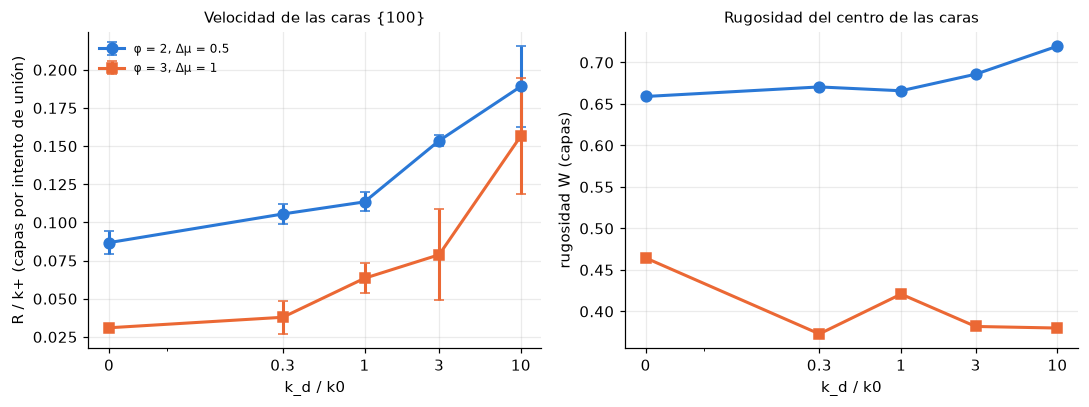

In [3]:
KD = [0.0, 0.3, 1.0, 3.0, 10.0]
CASOS_K = [(2.0, 0.5), (3.0, 1.0)]
params_k = [{"phi": phi, "delta_mu": dmu, "k_d": kd, "rng_seed": sd}
            for phi, dmu in CASOS_K for kd in KD for sd in (1, 2)]
res_k = en_cache("kossel_kd", lambda: run_parallel("kmc3d.experiments:kossel_face_growth", params_k))
tab_k = pd.DataFrame([{k: v for k, v in r.items() if k != "coords"} for r in res_k])
resumen_k = (tab_k.groupby(["phi", "delta_mu", "k_d"])
             .agg(R_k=("R/k+", "mean"), R_k_sd=("R/k+", "std"), W=("W", "mean"),
                  frac_saltos=("frac_saltos", "mean"), frac_rechazos=("frac_rechazos", "mean"),
                  segundos=("segundos", "mean"))
             .rename(columns={"R_k": "R/k+", "R_k_sd": "sd(R/k+)"}).reset_index())
display(resumen_k)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for i, (phi, dmu) in enumerate(CASOS_K):
    d = resumen_k[(resumen_k.phi == phi) & (resumen_k.delta_mu == dmu)]
    lab = f"φ = {phi:g}, Δμ = {dmu:g}"
    axes[0].errorbar(d["k_d"], d["R/k+"], yerr=d["sd(R/k+)"], color=COLORES[i], marker=MARCAS[i],
                     ms=7, lw=2, capsize=3, label=lab)
    axes[1].plot(d["k_d"], d["W"], color=COLORES[i], marker=MARCAS[i], ms=7, lw=2, label=lab)
for ax, yl in zip(axes, ["R / k+ (capas por intento de unión)", "rugosidad W (capas)"]):
    ax.set_xscale("symlog", linthresh=0.3)
    ax.set_xlabel("k_d / k0")
    ax.set_ylabel(yl)
    ax.set_xticks(KD)
    ax.set_xticklabels([f"{k:g}" for k in KD])
axes[0].legend(frameon=False, fontsize=8)
axes[0].set_title("Velocidad de las caras {100}", fontsize=10)
axes[1].set_title("Rugosidad del centro de las caras", fontsize=10)
fig.tight_layout()
guardar(fig, "kossel_R_W_vs_kd")
plt.show()

**Lectura.**
- **La difusión acelera las dos caras, y mucho más la lisa.** Con k_d = 10, R/k+ se
  multiplica por unos 2 con φ = 2 y por unos 5 con φ = 3. Los adátomos llegan a los
  escalones y a los núcleos 2D antes de despegarse: es el resultado clásico de Gilmer y
  Bennema.
- **Coste:** con k_d grande, más de la mitad de los eventos son saltos y un 30–40 %
  se rechaza (destinos sin otro vecino). Hacen falta muchos más eventos por unidad
  incorporada.
- **Rugosidad:** en la cara lisa (φ = 3) baja de 0.46 a ~0.38; los adátomos se
  incorporan a los escalones en vez de quedarse sueltos. En la de φ = 2 sube un poco
  (0.66 → 0.72): es una cara casi rugosa, y crecer más deprisa la desordena más.

### 2.3 Relajación de una varilla solo con difusión

Sin unión ni despegue (k0 = 10⁻¹²), N es constante y la forma solo puede cambiar por
difusión. La varilla de 4 × 4 × 24 debería acercarse a una forma compacta. Se mide
sobre el **fragmento conexo mayor** (`analysis.largest_cluster`): a φ bajo, el gas de
red en volumen infinito tiene más entropía que el cristal y se desprenden fragmentos.

Casos (2·10⁶ eventos cada uno):
- φ = 2.5 y φ = 3 con `"cube18"`;
- φ = 2.5 con `"bonds"`, que solo salta a vecinos por enlace y no puede cruzar
  aristas;
- φ = 1.5 con `"cube18"`, para ver la fragmentación.

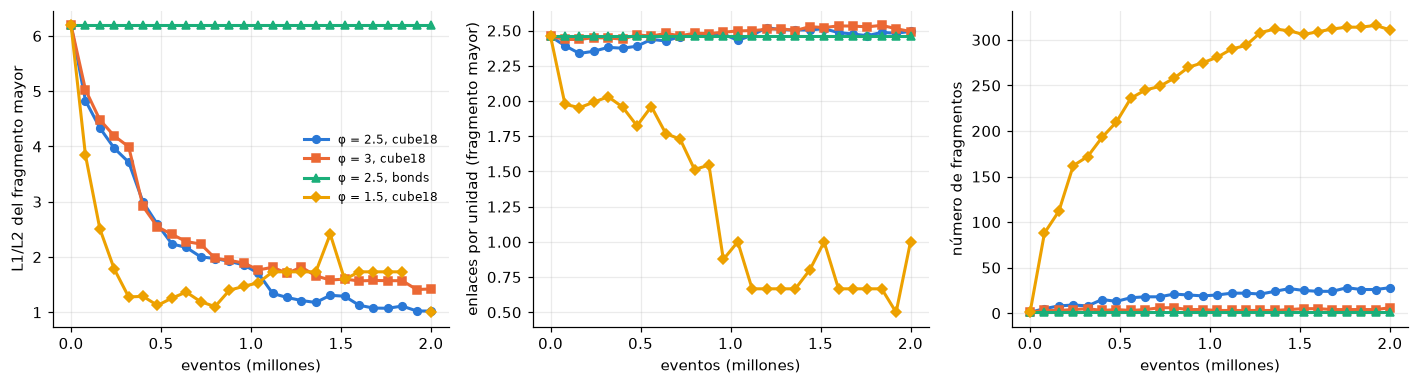

,caso,L1/L2 inicial,L1/L2 final,fragmentos,fracción en el mayor,rechazos / eventos,segundos
0,"φ = 2.5, cube18",6.191,1.021,28,0.891,0.733,42.407
1,"φ = 3, cube18",6.191,1.422,6,0.977,0.712,36.773
2,"φ = 2.5, bonds",6.191,6.191,1,1.000,1.000,4.576
3,"φ = 1.5, cube18",6.191,1.000,311,0.010,0.740,23.651


In [4]:
CASOS_V = [{"phi": 2.5, "hop_vectors": "cube18"}, {"phi": 3.0, "hop_vectors": "cube18"},
           {"phi": 2.5, "hop_vectors": "bonds"}, {"phi": 1.5, "hop_vectors": "cube18"}]
res_v = en_cache("varilla", lambda: run_parallel("kmc3d.experiments:relax_rod",
                                                 [dict(c, n_events=2_000_000) for c in CASOS_V]))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for i, r in enumerate(res_v):
    s = r["serie"]
    lab = f"φ = {r['phi']:g}, {r['hop_vectors']}"
    axes[0].plot(s["eventos"] / 1e6, s["L1/L2"], color=COLORES[i], marker=MARCAS[i], ms=5, lw=2, label=lab)
    axes[1].plot(s["eventos"] / 1e6, s["enlaces_por_unidad"], color=COLORES[i], marker=MARCAS[i], ms=5, lw=2)
    axes[2].plot(s["eventos"] / 1e6, s["fragmentos"], color=COLORES[i], marker=MARCAS[i], ms=5, lw=2)
for ax, yl in zip(axes, ["L1/L2 del fragmento mayor", "enlaces por unidad (fragmento mayor)",
                         "número de fragmentos"]):
    ax.set_xlabel("eventos (millones)")
    ax.set_ylabel(yl)
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
guardar(fig, "varilla_relajacion")
plt.show()
pd.DataFrame([{"caso": f"φ = {r['phi']:g}, {r['hop_vectors']}",
               "L1/L2 inicial": r["serie"]["L1/L2"].iloc[0], "L1/L2 final": r["serie"]["L1/L2"].iloc[-1],
               "fragmentos": r["serie"]["fragmentos"].iloc[-1],
               "fracción en el mayor": r["serie"]["frac_mayor"].iloc[-1],
               "rechazos / eventos": r["frac_rechazos"], "segundos": r["segundos"]} for r in res_v])

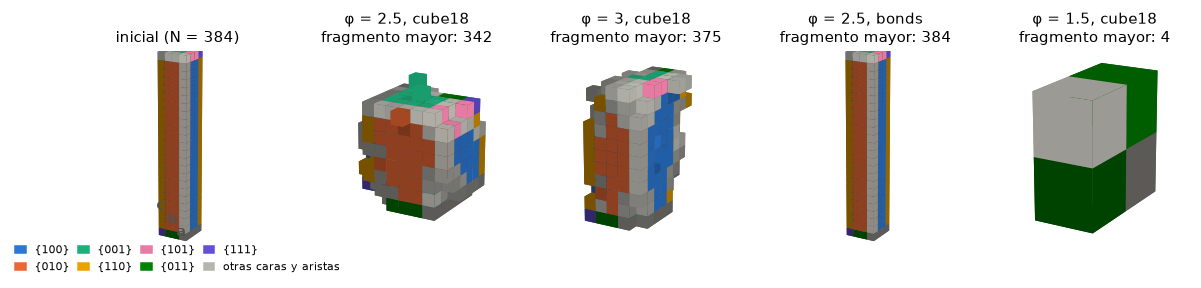

In [5]:
# Varilla inicial y final (fragmento mayor) coloreadas por faceta de Kossel
FACES_K = ((1, 0, 0), (0, 1, 0), (0, 0, 1), (1, 1, 0), (1, 0, 1), (0, 1, 1), (1, 1, 1))
g_v = presets.kossel(2.5)
fig = plt.figure(figsize=(13, 4.2))
paneles = [(f"inicial (N = {len(res_v[0]['inicial'])})", res_v[0]["inicial"])]
for r in res_v:
    mayor = an.largest_cluster(r["final"], g_v)
    paneles.append((f"φ = {r['phi']:g}, {r['hop_vectors']}\nfragmento mayor: {len(mayor)}", mayor))
for k, (tit, c) in enumerate(paneles):
    ax = fig.add_subplot(1, len(paneles), k + 1, projection="3d")
    render.render_crystal(c, g_v.cell, FACES_K, ax=ax, radius_cells=1.5, max_angle=15,
                          label_faces=False, legend=(k == 0), triad=(k == 0), title=tit)
guardar(fig, "varilla_formas")
plt.show()

**Lectura.**
- **`"cube18"` compacta la varilla.** L1/L2 baja de 6.2 a 1.0 con φ = 2.5 y a 1.4 con
  φ = 3 en 2·10⁶ eventos; con φ = 3 va más despacio porque la barrera de salto crece
  con φ.
- **Con `"bonds"` la varilla no cambia nada:** se rechazan todos los saltos. En una caja
  perfecta, un salto por enlace hacia fuera deja a la unidad sin otro vecino, y uno a lo
  largo de la cara cae en un sitio ocupado. Para relajar formas hacen falta saltos
  diagonales; para la cinética de escalones sobre una cara bastan los de enlace.
- **Fragmentación:** con φ = 1.5 el cristal se evapora en un gas de red (cientos de
  fragmentos). Con φ = 2.5 se desprende un ~10 % de las unidades y con φ = 3 un ~2 %.
  Es lo esperable en volumen infinito sin reservorio, no un error. Por eso las medidas
  de forma usan el fragmento mayor.
- **Enlaces por unidad:** al principio bajan aunque la forma se compacte. Las caras
  perfectas de la semilla se vuelven rugosas (entropía térmica) antes de que la varilla
  se acorte.

## 3. Visualizaciones nuevas

`kmc3d/render.py` sustituye a las nubes de puntos y a las proyecciones con moiré:
- `render_crystal`: superficie del cristal (caras expuestas de cada unidad) coloreada
  por **faceta**. Cada unidad de superficie se asigna a la familia (hkl) más próxima a
  su normal suavizada (`analysis.facet_labels`, radio 2.5 celdas, ángulo máximo 20°).
  Las unidades sin cara (aristas, zonas rugosas) van en gris. El sombreado sale de la
  normal suavizada y las etiquetas (hkl) se ponen en las caras visibles.
- `plot_polyhedron`: el poliedro continuo (Wulff), con los mismos colores por familia.
- `plot_thickness_maps`: proyección del **espesor** a lo largo de columnas de la red,
  como una imagen de TEM, sin moiré.
- `viz.animate_growth_3d(..., color_by="facet")`: animación por facetas (con
  `to_jshtml`, sin WebGL).

Colores: paleta categórica de 8 tonos con orden fijo. La 9.ª familia ((10-1)) y las
siguientes se agrupan con "otras caras y aristas".

Ejemplo: β-hematina con las energías **provisionales**, Δμ = 1, tasas simétricas,
semilla esférica de 70 Å y N = 40 000 (el caso base del notebook 01).

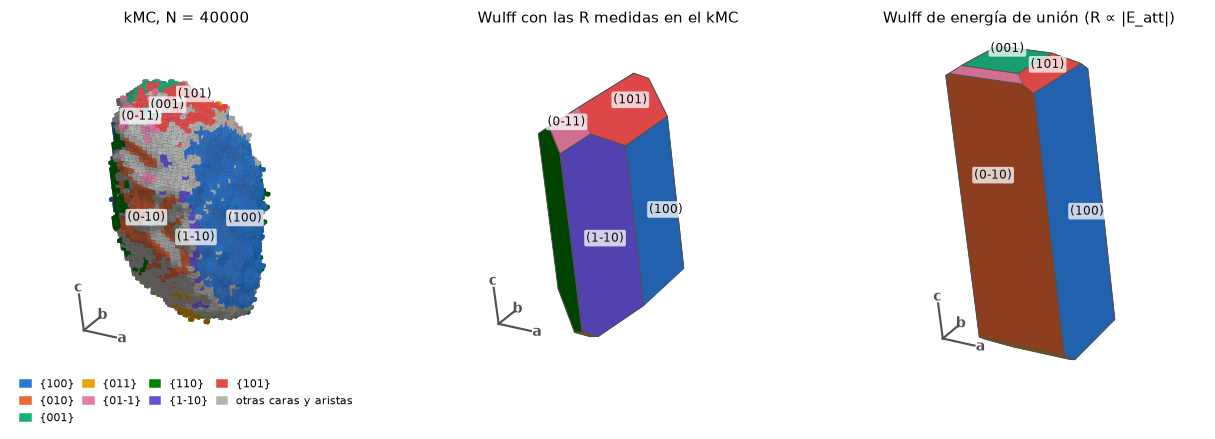

,kMC (facetas),Wulff cinético,Wulff E_att
familia,,,
(100),0.595,0.255,0.487
(010),0.082,0.000,0.325
(001),0.043,0.000,0.069
(011),0.034,0.010,0.052
(01-1),0.018,0.021,0.012
(110),0.046,0.263,0.000
(1-10),0.024,0.172,0.000
(101),0.133,0.127,0.035
(10-1),0.024,0.151,0.020


In [6]:
bh = presets.beta_hematin()


def corrida_provisional():
    kmc = KMC3D(bh, SplitRates.symmetric(bh, 1.0), seeds.sphere(70.0, bh.cell), rng_seed=1,
                track_faces=presets.BETA_HEMATIN_FACES)
    snaps, _ = kmc.run(n_max=40_000, max_events=3_000_000, record_every=5_000, snapshot_every=10_000)
    return snaps


snaps_prov = en_cache("bh_provisional", corrida_provisional)
final_prov = snaps_prov[-1][1]
# Velocidades medidas (plano medio) -> Wulff cinético; y Wulff de energía de unión
R_prov = an.face_growth_rates(an.face_mean_series(snaps_prov, bh, FACES))
caras_cin, tab_cin = an.wulff_faces(an.family_rates(R_prov), bh.cell)
caras_att, tab_att = an.wulff_faces(an.attachment_energy_rates(bh, FACES), bh.cell)
area_kmc = an.facet_areas(final_prov, bh.cell, FACES).set_index("familia")["fraccion"]

fig = plt.figure(figsize=(14, 5.2))
ax = fig.add_subplot(1, 3, 1, projection="3d")
render.render_crystal(final_prov, bh.cell, FACES, ax=ax, title=f"kMC, N = {len(final_prov)}")
ax = fig.add_subplot(1, 3, 2, projection="3d")
render.plot_polyhedron(caras_cin, FACES, ax=ax, cell=bh.cell, legend=False,
                       title="Wulff con las R medidas en el kMC")
ax = fig.add_subplot(1, 3, 3, projection="3d")
render.plot_polyhedron(caras_att, FACES, ax=ax, cell=bh.cell, legend=False,
                       title="Wulff de energía de unión (R ∝ |E_att|)")
guardar(fig, "bh_provisional_render_wulff")
plt.show()
pd.DataFrame({"kMC (facetas)": area_kmc, "Wulff cinético": tab_cin.set_index("familia")["fraccion"],
              "Wulff E_att": tab_att.set_index("familia")["fraccion"]}).fillna(0.0).round(3)

La tabla da la **fracción del área** de cada familia. En el kMC la medida es aproximada:
- las aristas y las zonas rugosas no se asignan a ninguna cara;
- el área de una cara plana se subestima en un error ~1/L (unos 25 % en una caja de 10
  celdas de lado, 8 % en una de 30; test `test_box_areas_converge`).

Hay dos diferencias que importan:
- **kMC frente a E_att:** la cinética no sigue a |E_att| (notebook 01, §5).
- **kMC frente a su propio Wulff cinético:** el Wulff construido con las R medidas da
  (110), (1-10) y (10-1) grandes y ninguna (010), justo al revés que el cristal. Mi
  hipótesis (sin comprobar): para una cara que no está desarrollada, el "plano medio"
  del recorte central es una arista redondeada. Su altura media queda por debajo de la
  envolvente y avanza más despacio, así que la R medida subestima la de esa dirección y
  el Wulff la hace aparecer. Por eso la calibración (§4) usa las áreas medidas sobre el
  cristal kMC, no las del Wulff cinético.

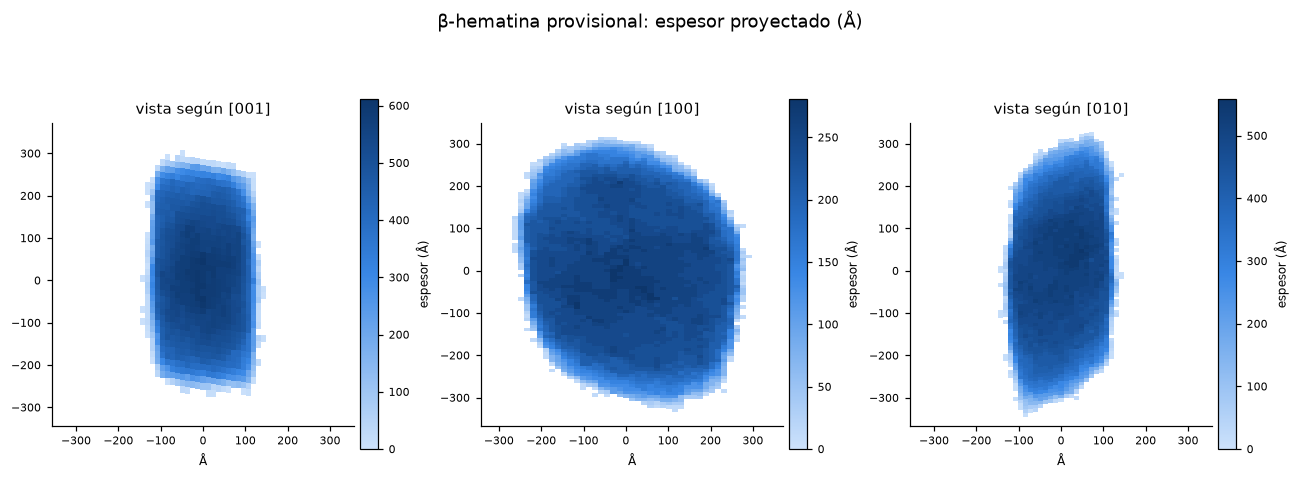

In [7]:
# Proyecciones de espesor (tipo TEM) a lo largo de c, a y b
axes = render.plot_thickness_maps(final_prov, bh.cell, title="β-hematina provisional: espesor proyectado (Å)")
guardar(plt.gcf(), "bh_provisional_espesor")
plt.show()

In [8]:
# Animación del crecimiento coloreada por faceta (matplotlib, sin WebGL)
anim = viz.animate_growth_3d(snaps_prov, bh.cell, color_by="facet", faces=FACES, max_frames=10,
                             figsize=(6.5, 6.0), title="β-hematina provisional, Δμ = 1")
html_anim = anim.to_jshtml()
plt.close(anim._fig)
HTML(html_anim)

In [9]:
# Sensibilidad de la asignación de facetas a sus dos parámetros (cristal provisional).
# Ángulo mínimo entre normales de familias distintas: (001)-(011) ≈ 28°, así que
# ángulos máximos de 15–20° no son ambiguos.
filas = []
for r_c, ang in [(1.5, 15), (2.0, 15), (2.5, 20), (3.0, 20), (3.0, 25)]:
    lab = an.facet_labels(final_prov, bh.cell, FACES, radius_cells=r_c, max_angle=ang)
    fr = an.facet_areas(final_prov, bh.cell, FACES, labels=lab).set_index("familia")["fraccion"]
    filas.append({"radio (celdas)": r_c, "ángulo máx.": ang,
                  "sin cara": float(np.mean(lab["family"] < 0)), **fr.round(3).to_dict()})
pd.DataFrame(filas)

,radio (celdas),ángulo máx.,sin cara,(100),(010),(001),(011),(01-1),(110),(1-10),(101),(10-1)
0,1.5,15,0.446,0.498,0.138,0.056,0.071,0.045,0.042,0.057,0.060,0.034
1,2.0,15,0.524,0.479,0.170,0.072,0.064,0.037,0.028,0.058,0.076,0.016
2,2.5,20,0.263,0.595,0.082,0.043,0.034,0.018,0.046,0.024,0.133,0.024
3,3.0,20,0.283,0.536,0.140,0.043,0.058,0.033,0.056,0.035,0.086,0.014
4,3.0,25,0.148,0.485,0.150,0.036,0.062,0.041,0.062,0.041,0.098,0.024


Las fracciones de las familias grandes ((100), (010), (101)) cambian poco entre 2.5/20°
y 3/25°. Las pequeñas dependen más de los parámetros, así que los criterios de §4 usan
cocientes entre familias grandes o umbrales holgados. Por defecto se usa 2.5 celdas y
20°.

## 4. Calibración de β-hematina con la morfología

### 4.1 Método

**Objetivo** (Solomonov et al. 2007; PLAN §7.2): agujas según c, caras laterales {100}
(la mayor) y {010} con anchura/espesor ≈ 3:1, extremos {011} y en menor medida {001}, y
sin {0-11}.

**Protocolo de cada corrida** (`calibration.run_candidate`):
- tasas simétricas y semilla esférica de 70 Å (~1000 unidades);
- crecimiento hasta N = 40 000 (unos 38 nm de lado), con medidas sobre el fragmento
  mayor;
- dimensiones L = √(12·var) a lo largo de c (L_c), de la anchura w (en el plano (100),
  perpendicular a c) y del espesor T (normal a (100));
- fracción de área de cada familia con `facet_areas`.

**Criterios** (`calibration.evaluate_criteria`; los umbrales los elijo yo, el plan solo
da "aguja", "≈ 3:1", "{011} > {001}" y "sin {0-11}"):

| # | Criterio | Condición |
|---|---|---|
| 1 | aguja según c | eje largo a ≤ 15° de c y L_c/W ≥ 1.5 |
| 2 | anchura/espesor | 2 ≤ W/T ≤ 4.5 |
| 3 | laterales | ({100}+{010}) ≥ 75 % de la zona [001] y {100} es la cara mayor |
| 4 | extremos | {011} > {001} > 0 y ({011}+{001}) ≥ 50 % de las caras que cortan c |
| 5 | sin {0-11} | área de {01-1} < 3 % |
| 6 | estacionaria | W/T y L_c/W cambian menos de un 15 % (en log) entre N/2 y N |

El 6 no es un dato observado. Es una condición de validez: si una cara no crece, la
forma la fija la semilla y no es una morfología de crecimiento.

J es una pérdida continua: suma de los cuadrados de las violaciones relativas, más el
error logarítmico de W/T respecto de 3. Sirve para ordenar candidatos que cumplen el
mismo número de criterios.

**Parámetros:** las 7 energías φ (con `overrides`), una escala común y Δμ.

In [10]:
# Qué enlaces cortan cada cara: |h·u| (0 = el enlace está en el plano de la cara)
cortes = pd.DataFrame({b.label: [abs(int(np.dot(f, b.vector))) for f in FACES] for b in bh.bonds},
                      index=[hkl_label(f) for f in FACES])
cortes

,[001],[10-1],[100],[010],[011],[01-1],[101]
(100),0,1,1,0,0,0,1
(010),0,0,0,1,1,1,0
(001),1,1,0,0,1,1,1
(011),1,1,0,1,2,0,1
(01-1),1,1,0,1,0,2,1
(110),0,1,1,1,1,1,1
(1-10),0,1,1,1,1,1,1
(101),1,0,1,0,1,1,2
(10-1),1,2,1,0,1,1,0


La tabla de cortes explica casi todo lo que sigue. Un enlace con |h·u| = 0 está en el
plano de la cara: la hace más lisa (cara F) y más lenta. Un enlace que la corta la
acelera.

- **(101)** tiene en su plano [10-1] (puentes de H) y [010]. Con las energías
  provisionales es una cara F lenta y forma los extremos, en vez de {011}.
- **(011)** tiene en su plano [100] y [01-1]. Con [100] = 0.4 kT no es una red 2D
  fuerte, así que se comporta casi como una cara S (rápida).
- **[100] y [101]** cortan (100): si se refuerzan, la cara lateral principal crece más
  y el cristal engorda (W/T baja).
- **[01-1]** corta (010), (101), (001) y dos veces (01-1), pero no (100) ni (011):
  ensancha el cristal (W/T sube), acorta (101) y elimina {0-11}.

### 4.2 Sensibilidad de un factor a la vez

Partiendo de las energías provisionales a Δμ = 1.5, se multiplica cada enlace por 0.5 y
por 2 (y la escala común por 0.8 y 1.25). El mapa muestra el cambio de cada métrica
respecto del caso base, como log(métrica / base): azul sube, naranja baja, gris no
cambia.

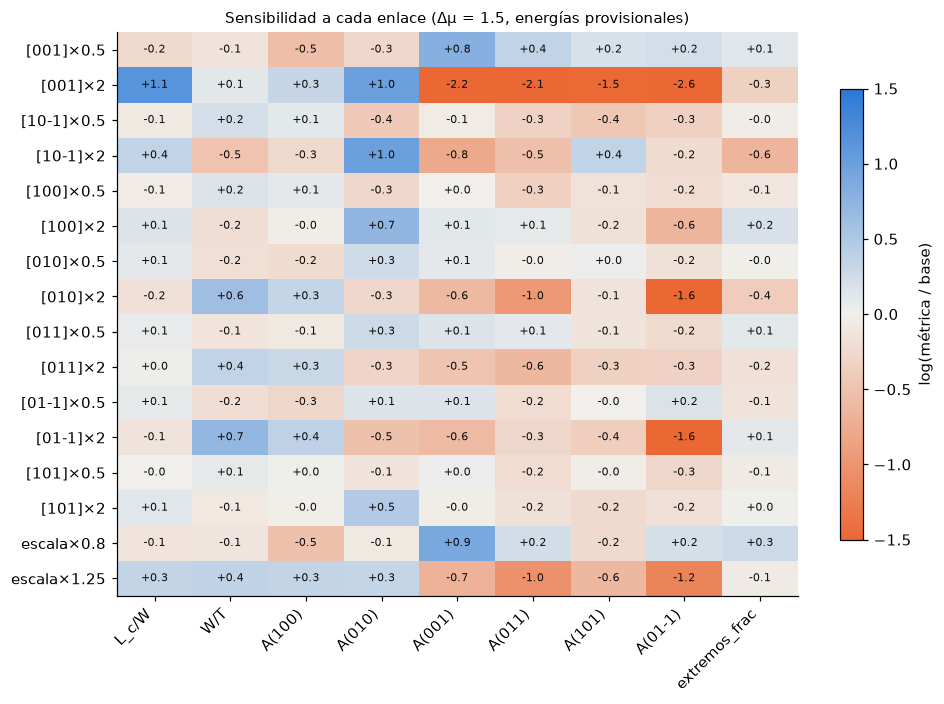

,n_criterios,J,angulo_c,deriva_W/T,L_c/W,W/T,A(100),A(010),A(001),A(011),A(101),A(01-1),extremos_frac,aguja_c,anchura_espesor,laterales,extremos,sin_0-11,estacionaria
nombre,,,,,,,,,,,,,,,,,,,
base,2,4.261,43.319,0.064,0.995,1.625,0.478,0.063,0.048,0.061,0.166,0.045,0.311,False,False,True,False,False,True
[001]×0.5,1,22.837,84.927,0.038,0.785,1.423,0.277,0.049,0.104,0.087,0.199,0.056,0.351,False,False,False,False,False,True
[001]×2,3,0.558,0.629,0.154,3.114,1.819,0.660,0.173,0.005,0.008,0.038,0.003,0.223,True,False,True,False,True,False
[10-1]×0.5,3,9.025,58.675,0.075,0.927,2.019,0.529,0.042,0.045,0.044,0.107,0.032,0.301,False,True,True,False,False,True
[10-1]×2,2,2.108,25.027,-0.014,1.427,1.001,0.372,0.174,0.022,0.036,0.238,0.036,0.164,False,False,True,False,False,True
[100]×0.5,2,8.631,57.464,0.049,0.944,1.900,0.521,0.049,0.048,0.043,0.143,0.036,0.283,False,False,True,False,False,True
[100]×2,3,0.797,16.789,0.041,1.148,1.344,0.463,0.131,0.053,0.066,0.142,0.024,0.372,False,False,True,False,True,True
[010]×0.5,1,1.469,26.468,0.026,1.091,1.358,0.379,0.082,0.052,0.059,0.172,0.038,0.306,False,False,False,False,False,True
[010]×2,4,16.653,74.958,0.111,0.841,3.005,0.667,0.049,0.026,0.024,0.145,0.009,0.209,False,True,True,False,True,True


In [11]:
BASE = presets.BETA_HEMATIN_ENERGIES_PROVISIONAL
oat = [{"nombre": "base", "delta_mu": 1.5}]
for lbl, phi in BASE.items():
    for f in (0.5, 2.0):
        oat.append({"nombre": f"{lbl}×{f:g}", "delta_mu": 1.5, "overrides": {lbl: phi * f}})
for s in (0.8, 1.25):
    oat.append({"nombre": f"escala×{s:g}", "delta_mu": 1.5, "scale": s})
res_oat = en_cache("oat", lambda: [{k: v for k, v in r.items() if k != "coords"}
                                   for r in cal.run_candidates(oat, verbose=False)])
df_oat = pd.DataFrame([{k: v for k, v in r.items() if k != "energias"} for r in res_oat]).set_index("nombre")
# En el mapa solo van métricas positivas (el cociente tiene sentido); el ángulo y la
# deriva (con signo) quedan en la tabla
METRICAS = ["L_c/W", "W/T", "A(100)", "A(010)", "A(001)", "A(011)", "A(101)", "A(01-1)", "extremos_frac"]
cambio = np.log((df_oat[METRICAS].clip(lower=1e-3)) / df_oat.loc["base", METRICAS].clip(lower=1e-3))
fig, ax = plt.subplots(figsize=(9, 6.5))
lim = 1.5
im = ax.imshow(cambio.drop(index="base").clip(-lim, lim), cmap=DIVERGENTE, vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(len(METRICAS)), METRICAS, rotation=45, ha="right")
ax.set_yticks(range(len(cambio) - 1), cambio.index[1:])
ax.grid(False)
for (i, j), v in np.ndenumerate(cambio.drop(index="base").to_numpy()):
    ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=7, color="#0b0b0b")
fig.colorbar(im, ax=ax, label="log(métrica / base)", shrink=0.8)
ax.set_title("Sensibilidad a cada enlace (Δμ = 1.5, energías provisionales)", fontsize=10)
fig.tight_layout()
guardar(fig, "calibracion_sensibilidad")
plt.show()
df_oat[["n_criterios", "J", "angulo_c", "deriva_W/T"] + METRICAS + list(cal.CRITERIOS)]

**Lectura** (el caso base cumple 2 de 6: una lámina con el eje largo a 43° de c).
- **[001]×2** da la aguja (L_c/W ≈ 3, eje a menos de 1° de c), pero achica todas las
  caras de los extremos por igual: los extremos siguen siendo sobre todo (101).
- **[01-1]×2** duplica W/T (hasta 3.3) y reduce (01-1) y (101). Además, la (100) deja
  de crecer (deriva de W/T 0.15).
- **[100]×2** es el único cambio de un enlace que sube la fracción de {011}+{001} en
  los extremos y a la vez acerca el eje a c (de 43° a 17°). Bajar la escala la sube
  más, pero el eje se va a 71° de c.
- **[010]×2** también sube W/T, pero el eje largo se va hacia la anchura (75° de c).
- **escala×1.25** (más anisotropía, como bajar T) cumple 4. Ningún cambio de un solo
  enlace cumple los 6, así que hay que combinarlos: rejilla de §4.3.

### 4.3 Rejilla dirigida

Con lo anterior, la rejilla se centra en los enlaces que separan las caras observadas:
- Δμ ∈ {1, 1.5, 2};
- [001] ∈ {3, 3.6};
- [01-1] ∈ {1.1, 1.7, 2.3, 2.9, 3.5};
- [100] ∈ {0.4, 1.2, 1.6};
- [101] ∈ {0.3, 0.7, 1.1};
- el resto como las provisionales y escala 1.

Son 270 corridas (semilla del RNG 1). En exploraciones previas, las escalas 1.15–1.3 no
añadían candidatos nuevos: la escala común actúa casi como Δμ.

270 corridas; cumplen los 6 criterios: 7


,aguja_c,anchura_espesor,laterales,extremos,sin_0-11,estacionaria
fracción que cumple,0.715,0.452,0.881,0.359,0.989,0.452


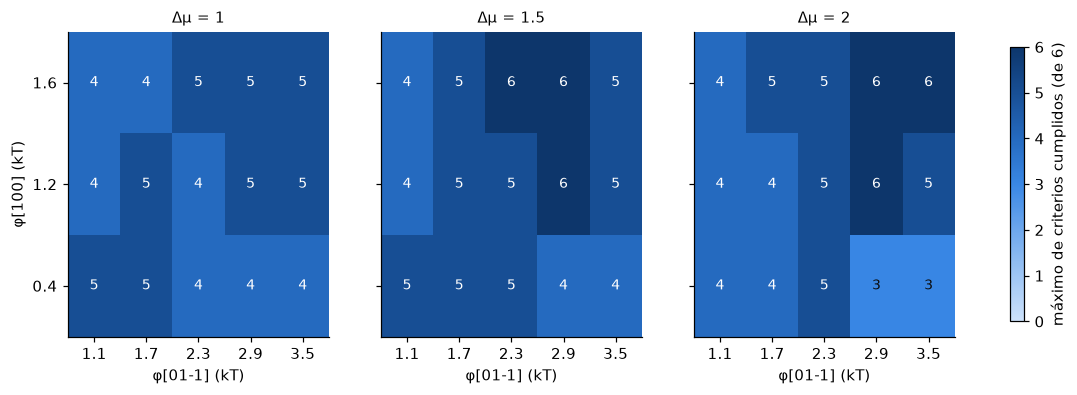

In [12]:
import itertools

REJILLA = list(itertools.product((1.0, 1.5, 2.0), (3.0, 3.6), (1.1, 1.7, 2.3, 2.9, 3.5),
                                 (0.4, 1.2, 1.6), (0.3, 0.7, 1.1)))
cand_rej = [{"nombre": f"d{d}_001={a}_01-1={b}_100={c}_101={e}", "delta_mu": d,
             "overrides": {"[001]": a, "[01-1]": b, "[100]": c, "[101]": e}}
            for d, a, b, c, e in REJILLA]
res_rej = en_cache("rejilla", lambda: [{k: v for k, v in r.items() if k != "coords"}
                                       for r in cal.run_candidates(cand_rej, verbose=False)])
df_rej = cal.results_frame(res_rej)
for k in ("[001]", "[01-1]", "[100]", "[101]"):
    df_rej[k] = df_rej["overrides"].map(lambda o: o[k])
print(f"{len(df_rej)} corridas; cumplen los 6 criterios: {(df_rej.n_criterios == 6).sum()}")
display(df_rej[list(cal.CRITERIOS)].mean().rename("fracción que cumple").to_frame().T)

# Mapa: máximo de criterios cumplidos (sobre [001] y [101]) para cada Δμ, [100] y [01-1]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, dmu in zip(axes, (1.0, 1.5, 2.0)):
    m = (df_rej[df_rej.delta_mu == dmu].pivot_table(index="[100]", columns="[01-1]",
                                                     values="n_criterios", aggfunc="max"))
    im = ax.imshow(m.to_numpy(), cmap=AZULES, vmin=0, vmax=6, origin="lower", aspect="auto")
    ax.set_xticks(range(m.shape[1]), [f"{x:g}" for x in m.columns])
    ax.set_yticks(range(m.shape[0]), [f"{x:g}" for x in m.index])
    ax.grid(False)
    for (i, j), v in np.ndenumerate(m.to_numpy()):
        ax.text(j, i, f"{v:d}", ha="center", va="center", fontsize=9,
                color="white" if v >= 4 else "#0b0b0b")
    ax.set_xlabel("φ[01-1] (kT)")
    ax.set_title(f"Δμ = {dmu:g}", fontsize=10)
axes[0].set_ylabel("φ[100] (kT)")
fig.colorbar(im, ax=axes, label="máximo de criterios cumplidos (de 6)", shrink=0.9)
guardar(fig, "calibracion_rejilla")
plt.show()

In [13]:
COLS = ["nombre", "n_criterios", "J", "L_c/W", "W/T", "angulo_c", "laterales_frac", "extremos_frac",
        "A(100)", "A(010)", "A(011)", "A(001)", "A(101)", "A(01-1)", "deriva_W/T", "T/T_semilla"]
df_rej[COLS].head(12)

,nombre,n_criterios,J,L_c/W,W/T,angulo_c,laterales_frac,extremos_frac,A(100),A(010),A(011),A(001),A(101),A(01-1),deriva_W/T,T/T_semilla
0,d2.0_001=3.6_01-1=2.9_100=1.2_101=0.7,6,0.004,1.698,2.812,12.217,0.916,0.572,0.706,0.108,0.055,0.008,0.033,0.003,0.117,1.495
1,d2.0_001=3.0_01-1=3.5_100=1.6_101=1.1,6,0.040,1.772,2.454,12.472,0.908,0.710,0.644,0.142,0.085,0.010,0.025,0.002,0.078,1.629
2,d1.5_001=3.0_01-1=2.9_100=1.2_101=1.1,6,0.063,2.473,2.334,4.681,0.907,0.582,0.655,0.170,0.046,0.006,0.027,0.001,0.136,1.492
3,d1.5_001=3.6_01-1=2.9_100=1.6_101=0.7,6,0.089,3.853,2.225,2.870,0.901,0.598,0.659,0.189,0.031,0.004,0.018,0.002,0.141,1.335
4,d2.0_001=3.6_01-1=2.9_100=1.6_101=0.7,6,0.098,2.099,2.193,6.581,0.910,0.556,0.632,0.170,0.058,0.008,0.042,0.003,0.112,1.647
5,d1.5_001=3.0_01-1=2.3_100=1.6_101=0.3,6,0.120,1.777,2.123,9.907,0.925,0.638,0.652,0.155,0.063,0.018,0.034,0.005,0.027,1.771
6,d2.0_001=3.0_01-1=2.9_100=1.2_101=1.1,6,0.139,1.675,2.067,13.598,0.916,0.538,0.623,0.165,0.060,0.015,0.039,0.005,0.070,1.849
7,d1.5_001=3.0_01-1=2.9_100=1.2_101=0.7,5,0.018,1.814,3.338,12.815,0.927,0.548,0.725,0.108,0.047,0.009,0.033,0.004,0.162,1.323
8,d2.0_001=3.6_01-1=2.3_100=1.2_101=0.3,5,0.053,1.631,2.404,9.001,0.894,0.469,0.679,0.099,0.050,0.011,0.053,0.005,0.148,1.670
9,d1.0_001=3.0_01-1=2.3_100=1.6_101=0.3,5,0.058,2.944,2.487,2.251,0.917,0.501,0.673,0.171,0.029,0.010,0.029,0.002,0.163,1.352


### 4.4 Robustez frente a la semilla del RNG

Los 8 mejores de la rejilla (por criterios y J) se repiten con las semillas 2 a 5. Se
elige el candidato con la **mayor media de criterios cumplidos** y, a igualdad, el menor
J medio. Un candidato que solo cumple con una semilla no está calibrado: es ruido.

In [14]:
TOP = df_rej.head(8)
cand_rob = [{"nombre": r.nombre, "delta_mu": r.delta_mu, "overrides": r.overrides, "rng_seed": sd}
            for r in TOP.itertuples() for sd in (2, 3, 4, 5)]
res_rob = en_cache("robustez", lambda: cal.run_candidates(cand_rob, verbose=False))
todas = pd.concat([pd.DataFrame([{k: v for k, v in r.items() if k not in ("coords", "energias")}
                                 for r in res_rob]),
                   TOP.assign(rng_seed=1)], ignore_index=True)
rob = (todas.groupby("nombre")
       .agg(semillas=("J", "size"), criterios_media=("n_criterios", "mean"),
            criterios_min=("n_criterios", "min"), J_media=("J", "mean"),
            WT=("W/T", "mean"), WT_sd=("W/T", "std"), LcW=("L_c/W", "mean"), angulo_c=("angulo_c", "mean"),
            extremos=("extremos_frac", "mean"), deriva_WT=("deriva_W/T", "mean"))
       .sort_values(["criterios_media", "J_media"], ascending=[False, True]))
display(rob)
display(todas.groupby("nombre")[list(cal.CRITERIOS)].mean().loc[rob.index]
        .rename(columns=lambda c: f"{c} (frac.)"))
ELEGIDO = TOP.set_index("nombre").loc[rob.index[0]]
print("Elegido:", rob.index[0])

,semillas,criterios_media,criterios_min,J_media,WT,WT_sd,LcW,angulo_c,extremos,deriva_WT
nombre,,,,,,,,,,
d1.5_001=3.0_01-1=2.3_100=1.6_101=0.3,5,6.0,6,0.112,2.155,0.102,1.806,9.893,0.581,0.074
d2.0_001=3.0_01-1=3.5_100=1.6_101=1.1,5,5.8,5,0.053,2.511,0.188,1.712,13.176,0.687,0.116
d1.5_001=3.0_01-1=2.9_100=1.2_101=1.1,5,5.8,5,0.066,2.354,0.151,2.497,5.099,0.581,0.125
d2.0_001=3.0_01-1=2.9_100=1.2_101=1.1,5,5.8,5,0.146,2.053,0.093,1.644,13.072,0.559,0.082
d2.0_001=3.6_01-1=2.9_100=1.6_101=0.7,5,5.6,5,0.133,2.246,0.110,2.207,5.989,0.603,0.151
d2.0_001=3.6_01-1=2.9_100=1.2_101=0.7,5,5.4,4,0.013,2.751,0.154,1.730,11.869,0.547,0.135
d1.5_001=3.0_01-1=2.9_100=1.2_101=0.7,5,5.2,5,0.142,3.034,0.183,1.670,13.095,0.559,0.175
d1.5_001=3.6_01-1=2.9_100=1.6_101=0.7,5,5.2,5,0.286,2.352,0.241,3.642,2.219,0.608,0.199


,aguja_c (frac.),anchura_espesor (frac.),laterales (frac.),extremos (frac.),sin_0-11 (frac.),estacionaria (frac.)
nombre,,,,,,
d1.5_001=3.0_01-1=2.3_100=1.6_101=0.3,1.0,1.0,1.0,1.0,1.0,1.0
d2.0_001=3.0_01-1=3.5_100=1.6_101=1.1,1.0,1.0,1.0,1.0,1.0,0.8
d1.5_001=3.0_01-1=2.9_100=1.2_101=1.1,1.0,1.0,1.0,1.0,1.0,0.8
d2.0_001=3.0_01-1=2.9_100=1.2_101=1.1,1.0,0.8,1.0,1.0,1.0,1.0
d2.0_001=3.6_01-1=2.9_100=1.6_101=0.7,1.0,1.0,1.0,1.0,1.0,0.6
d2.0_001=3.6_01-1=2.9_100=1.2_101=0.7,0.8,1.0,1.0,0.8,1.0,0.8
d1.5_001=3.0_01-1=2.9_100=1.2_101=0.7,0.8,1.0,1.0,1.0,1.0,0.4
d1.5_001=3.6_01-1=2.9_100=1.6_101=0.7,1.0,1.0,1.0,1.0,1.0,0.2


Elegido: d1.5_001=3.0_01-1=2.3_100=1.6_101=0.3


### 4.5 ¿Se mantiene la forma al crecer más?

El elegido se repite hasta N = 120 000 (3 veces el volumen) con las semillas 1 a 3. Si
la morfología es de crecimiento, los criterios deben mantenerse; si depende de la
semilla, W/T y L_c/W seguirán derivando.

In [15]:
cand_big = [{"nombre": f"N120k_s{sd}", "delta_mu": ELEGIDO.delta_mu, "overrides": ELEGIDO.overrides,
             "rng_seed": sd, "n_max": 120_000, "max_events": 10_000_000, "snapshot_every": 30_000}
            for sd in (1, 2, 3)]
res_big = en_cache("tamano", lambda: cal.run_candidates(cand_big, verbose=False))
comp = pd.concat([todas[todas.nombre == rob.index[0]].assign(N_objetivo=40_000),
                  pd.DataFrame([{k: v for k, v in r.items() if k not in ("coords", "energias")}
                                for r in res_big]).assign(N_objetivo=120_000)], ignore_index=True)
comp[["N_objetivo", "rng_seed", "n_criterios", "J", "L_c/W", "W/T", "angulo_c", "extremos_frac",
      "A(100)", "A(010)", "A(011)", "A(001)", "A(101)", "deriva_W/T", "deriva_L_c/W", "segundos"]
     + list(cal.CRITERIOS)]

,N_objetivo,rng_seed,n_criterios,J,L_c/W,W/T,angulo_c,extremos_frac,A(100),A(010),...,A(101),deriva_W/T,deriva_L_c/W,segundos,aguja_c,anchura_espesor,laterales,extremos,sin_0-11,estacionaria
0,40000,2,6,0.089,1.838,2.225,10.390,0.526,0.650,0.145,...,0.047,0.110,0.040,9.688,True,True,True,True,True,True
1,40000,3,6,0.124,1.731,2.111,10.371,0.576,0.630,0.156,...,0.047,0.105,0.049,7.092,True,True,True,True,True,True
2,40000,4,6,0.153,1.861,2.030,9.232,0.591,0.631,0.171,...,0.040,0.076,0.010,7.701,True,True,True,True,True,True
3,40000,5,6,0.073,1.821,2.289,9.567,0.573,0.653,0.147,...,0.047,0.053,0.045,8.565,True,True,True,True,True,True
4,40000,1,6,0.120,1.777,2.123,9.907,0.638,0.652,0.155,...,0.034,0.027,0.029,8.636,True,True,True,True,True,True
5,120000,1,6,0.043,1.893,2.436,8.856,0.642,0.681,0.144,...,0.034,0.078,0.028,14.408,True,True,True,True,True,True
6,120000,2,6,0.044,1.953,2.434,9.091,0.619,0.683,0.147,...,0.033,0.070,0.026,14.457,True,True,True,True,True,True
7,120000,3,6,0.046,1.838,2.423,9.691,0.643,0.668,0.145,...,0.035,0.099,0.030,13.885,True,True,True,True,True,True


### 4.6 El cristal calibrado

Energías provisionales frente a calibradas, la teoría de energía de unión con las
calibradas, y el cristal (semilla 1, N = 120 000) junto a su Wulff cinético.

,[001],[10-1],[100],[010],[011],[01-1],[101],Δμ
provisional,2.4,1.0,0.4,0.9,0.5,1.1,0.3,—
calibrada (efectiva),3.0,1.0,1.6,0.9,0.5,2.3,0.3,1.5


,hkl,h,k,l,d_hkl,E_slice,E_att,E_att_frac,caracter,R_att_rel
0,(100),1,0,0,11.992,6.7,-2.9,0.302,F,1.000
1,(010),0,1,0,14.541,5.9,-3.7,0.385,F,1.276
2,(011),0,1,1,6.937,3.9,-5.7,0.594,F,1.966
3,(110),1,1,0,8.678,3.0,-6.6,0.687,S,2.276
4,(1-10),1,-1,0,9.957,3.0,-6.6,0.687,S,2.276
5,(001),0,0,1,7.982,2.5,-7.1,0.740,F,2.448
6,(01-1),0,1,-1,7.058,2.1,-7.5,0.781,F,2.586
7,(101),1,0,1,6.305,1.9,-7.7,0.802,F,2.655
8,(10-1),1,0,-1,7.046,1.2,-8.4,0.875,F,2.897


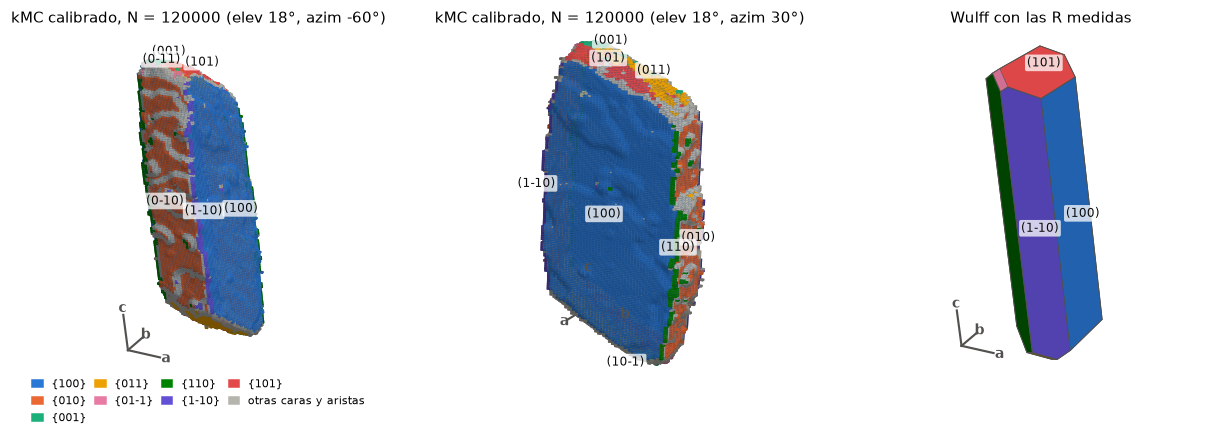

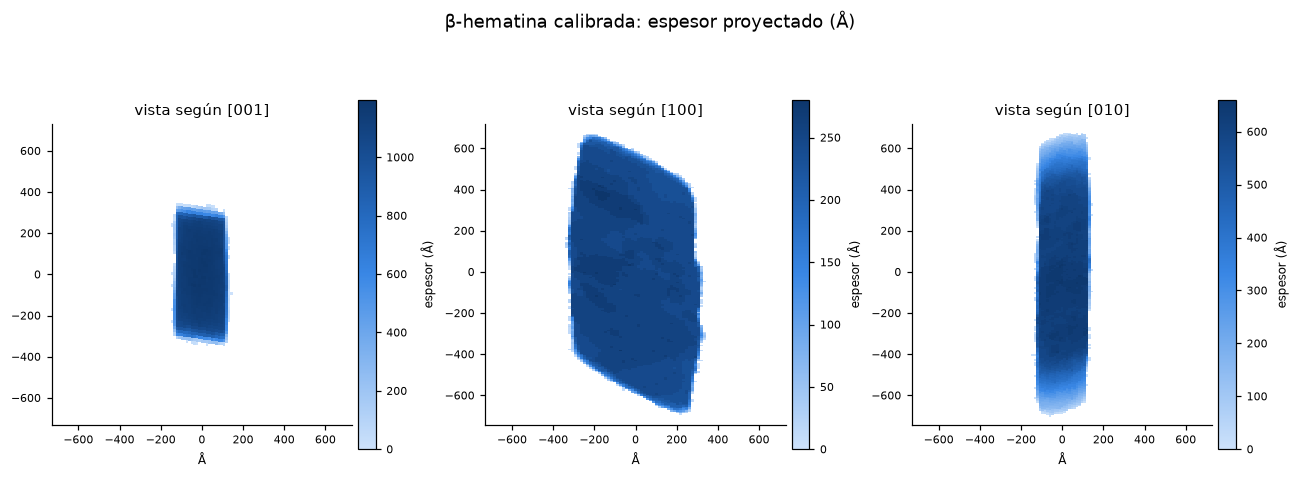

,kMC (facetas),Wulff cinético
(001),0.015,0.000
(01-1),0.003,0.004
(010),0.144,0.000
(011),0.064,0.013
(1-10),0.021,0.176
(10-1),0.007,0.054
(100),0.681,0.376
(101),0.034,0.095
(110),0.031,0.282


In [16]:
E_cal = cal.energies_from_params(1.0, ELEGIDO.overrides)
bh_cal = presets.beta_hematin(E_cal)
display(pd.DataFrame({"provisional": BASE, "calibrada (efectiva)": E_cal}).T
        .assign(**{"Δμ": ["—", ELEGIDO.delta_mu]}))
display(bh_cal.face_table(FACES).sort_values("R_att_rel", ignore_index=True))

r_big = res_big[0]
R_cal = {parse_hkl(k[1:]): v for k, v in r_big.items() if k.startswith("R(")}
caras_cal, tab_cal = an.wulff_faces(R_cal, bh_cal.cell)
fig = plt.figure(figsize=(14, 5.2))
for k, (el, az) in enumerate(((18, -60), (18, 30))):
    ax = fig.add_subplot(1, 3, k + 1, projection="3d")
    render.render_crystal(r_big["coords"], bh_cal.cell, FACES, ax=ax, elev=el, azim=az, legend=(k == 0),
                          title=f"kMC calibrado, N = {r_big['N']} (elev {el}°, azim {az}°)")
ax = fig.add_subplot(1, 3, 3, projection="3d")
render.plot_polyhedron(caras_cal, FACES, ax=ax, cell=bh_cal.cell, legend=False,
                       title="Wulff con las R medidas")
guardar(fig, "bh_calibrado_render")
plt.show()
axes = render.plot_thickness_maps(r_big["coords"], bh_cal.cell, title="β-hematina calibrada: espesor proyectado (Å)")
guardar(plt.gcf(), "bh_calibrado_espesor")
plt.show()
pd.DataFrame({"kMC (facetas)": pd.Series({k[1:]: v for k, v in r_big.items()
                                          if k.startswith("A(")}),
              "Wulff cinético": tab_cal.set_index("familia")["fraccion"]}).fillna(0.0).round(3)

**Lectura.**
- **Forma del cristal:** una lámina alargada según c, con (100) dominante, (010) en los
  costados y extremos (011)+(001) con algo de (101).
- **E_att con las energías calibradas** ordena (100) < (010) < (011) < (110) < (001) <
  (01-1) < (101) < (10-1). Es el orden que pide la morfología observada, con (011) más
  lenta que (001) y (01-1) rápida, aunque la calibración se hizo con el kMC.
- **El Wulff cinético vuelve a no coincidir** con las facetas del cristal (ver §3).

### 4.7 Efecto de la difusión en el cristal calibrado

Con tasas simétricas, un adátomo con energía de enlace E salta a k_d·e^{−(E−E_kink)} por
dirección y se despega a k0·e^{−Δμ/2 − (E−E_kink)/2}. El cociente es

  Λ(E) = (k_d/k0) · e^{Δμ/2} · e^{−(E−E_kink)/2}.

Con las energías calibradas, E_kink = Σφ = 9.6 kT, así que Λ es muy grande para los
adátomos poco unidos. Para uno unido solo por [001] (E = 3 kT), Λ ≈ 57·k_d. En una
prueba previa con un candidato vecino, k_d = 1 no llegó a N = 40 000 en 3·10⁶ eventos.
Se usa k_d ∈ {0.01, 0.03, 0.1} con dos semillas.

E_kink = 9.6 kT;  Λ(E = 3 kT) = 57·k_d


,nombre,rng_seed,Λ(E=3),n_criterios,J,L_c/W,W/T,angulo_c,extremos_frac,A(100),A(011),A(101),deriva_W/T,eventos,frac_saltos,segundos
0,kd=0,1,0.000,6,0.120,1.777,2.123,9.907,0.638,0.652,0.063,0.034,0.027,133283,0.000,5.115
1,kd=0,2,0.000,6,0.089,1.838,2.225,10.390,0.526,0.650,0.050,0.047,0.110,133223,0.000,5.166
2,kd=0.01,1,0.574,6,0.034,1.596,2.496,13.313,0.598,0.683,0.065,0.040,0.035,251762,0.336,15.000
3,kd=0.01,2,0.574,6,0.135,1.820,2.077,10.957,0.577,0.622,0.065,0.048,0.123,256858,0.335,15.092
4,kd=0.03,1,1.722,6,0.117,1.767,2.130,8.633,0.575,0.634,0.067,0.050,0.148,460884,0.496,27.522
5,kd=0.03,2,1.722,6,0.117,1.766,2.132,10.079,0.588,0.634,0.063,0.042,0.101,466906,0.495,27.428
6,kd=0.1,1,5.740,6,0.100,1.677,2.187,10.933,0.612,0.640,0.077,0.045,0.082,1038448,0.601,59.537
7,kd=0.1,2,5.740,5,0.142,1.742,2.058,9.577,0.490,0.623,0.052,0.058,0.094,1055287,0.603,59.574


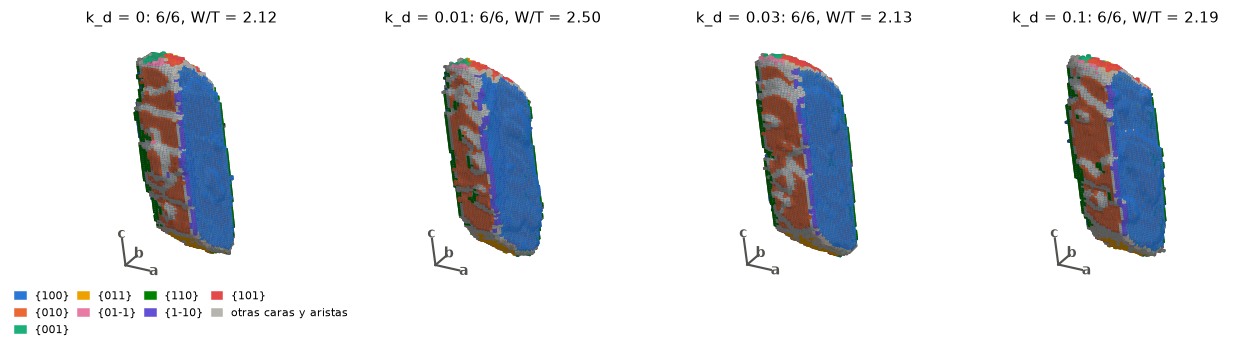

In [17]:
E_kink = sum(E_cal.values())
lam = lambda kd, E: kd * np.exp(ELEGIDO.delta_mu / 2) * np.exp(-(E - E_kink) / 2)
print(f"E_kink = {E_kink:.1f} kT;  Λ(E = 3 kT) = {lam(1.0, 3.0):.0f}·k_d")
cand_dif = [{"nombre": f"kd={kd:g}", "delta_mu": ELEGIDO.delta_mu, "overrides": ELEGIDO.overrides,
             "k_d": kd, "rng_seed": sd} for kd in (0.0, 0.01, 0.03, 0.1) for sd in (1, 2)]
res_dif = en_cache("difusion_calibrado", lambda: cal.run_candidates(cand_dif, verbose=False))
df_dif = pd.DataFrame([{k: v for k, v in r.items() if k not in ("coords", "energias")} for r in res_dif])
df_dif["Λ(E=3)"] = df_dif["k_d"].map(lambda kd: lam(kd, 3.0))
df_dif["frac_saltos"] = df_dif["saltos"] / df_dif["eventos"]
display(df_dif[["nombre", "rng_seed", "Λ(E=3)", "n_criterios", "J", "L_c/W", "W/T", "angulo_c",
                "extremos_frac", "A(100)", "A(011)", "A(101)", "deriva_W/T", "eventos", "frac_saltos",
                "segundos"]])
fig = plt.figure(figsize=(14, 4.6))
for k, kd in enumerate((0.0, 0.01, 0.03, 0.1)):
    r = next(r for r in res_dif if r["k_d"] == kd and r["rng_seed"] == 1)
    ax = fig.add_subplot(1, 4, k + 1, projection="3d")
    render.render_crystal(r["coords"], bh_cal.cell, FACES, ax=ax, legend=(k == 0), label_faces=False,
                          title=f"k_d = {kd:g}: {r['n_criterios']}/6, W/T = {r['W/T']:.2f}")
guardar(fig, "bh_calibrado_difusion")
plt.show()

**Lectura.** Hasta k_d = 0.1 (Λ ≈ 6 saltos por despegue de un adátomo unido por [001])
la morfología calibrada **no cambia de forma apreciable**. 7 de las 8 corridas cumplen
los 6 criterios; la otra falla "extremos" por poco (0.49 frente a 0.5). W/T, L_c/W y el
ángulo quedan dentro de la dispersión entre semillas. En cambio, el coste se multiplica
por 8 en eventos y por 12 en tiempo. Con k_d ≳ 1 no se puede comprobar con este motor
en Python puro (ver D10 y F5 en el plan). La calibración vale, por tanto, para
difusión débil.

## 5. Conclusiones

**Difusión superficial (F4)**

1. **Implementación.** La difusión es un evento de salto con balance detallado
   respecto de la energía de enlace. Sin difusión, las trayectorias son idénticas bit a
   bit a las de antes.
2. **Kossel.** La difusión acelera sobre todo la cara lisa: R/k+ se multiplica por ~5
   con φ = 3, Δμ = 1 y k_d = 10, y por ~2 con φ = 2, Δμ = 0.5. Es el resultado clásico de
   Gilmer y Bennema: los adátomos llegan a los escalones antes de despegarse.
3. **Vectores de salto.** Los saltos por enlace no relajan formas: en una caja perfecta
   se rechazan todos. Con `"cube18"` la varilla pasa de L1/L2 = 6.2 a 1.0.
4. **Fragmentación.** Sin reservorio, con φ bajo y difusión el cristal se evapora (gas
   de red en volumen infinito); con φ = 2.5 se pierde ~10 %. Las medidas de forma usan
   el fragmento mayor.
5. **Coste.** Con k_d grande, más de la mitad de los eventos son saltos y un 30–40 %
   se rechaza. En β-hematina con tasas simétricas, un adátomo débil salta ~60·k_d veces
   por cada despegue (E_kink ≈ 10 kT), así que solo se puede usar k_d ≲ 0.1.

**Visualizaciones**

6. **Herramientas nuevas.** `render_crystal` (superficie por facetas), `plot_polyhedron`
   (Wulff), `plot_thickness_maps` (espesor tipo TEM, sin moiré) y la animación por
   facetas sustituyen a las nubes de puntos.
7. **Áreas por faceta.** Se miden sobre el cristal con un sesgo conocido: aristas sin
   asignar y un error ~1/L.
8. **Forma kMC frente a su Wulff cinético.** El Wulff construido con las R medidas
   (plano medio) no reproduce el cristal kMC. Da caras (110)/(1-10) grandes que el
   cristal no tiene, y ninguna (010), que sí tiene. Hipótesis: en una cara no
   desarrollada el plano medio mide una arista redondeada y subestima R. La calibración
   usa el cristal kMC. Revisar la medida de R en esas caras queda pendiente.

**Calibración de β-hematina (F3, con la morfología)**

9. **Energías provisionales: 2 de 6 criterios.** Sale una lámina con el eje a 43° de c
   y extremos (101).
10. **Mecanismo** (tabla de cortes |h·u|):
    - (101) es F por [10-1] y [010];
    - los extremos {011} exigen un [100] fuerte;
    - [01-1] da la anchura (W/T) y elimina {0-11}.
11. **Candidato calibrado.** Es el único que cumple los 6 criterios con 5 semillas:
    Δμ = 1.5, [001] = 3.0, [100] = 1.6, [01-1] = 2.3 y el resto como las provisionales.
    Con N = 120 000 sigue cumpliéndolos (3 semillas), con W/T = 2.43 y L_c/W ≈ 1.9.
12. **E_att con las energías calibradas** ordena las caras como se observa:
    (100) < (010) < (011) < (110) < (001) < (01-1) < (101) < (10-1). En particular,
    (011) queda antes que (001), aunque el ajuste se hizo con el kMC y no con E_att.
13. **Difusión débil** (k_d ≤ 0.1, Λ ≲ 6) no cambia la morfología calibrada (7 de 8
    corridas cumplen 6/6) y multiplica el coste por ~10.

**Límites (no ser complaciente)**

- Los criterios son desigualdades cualitativas y la solución **no es única**: varios
  candidatos vecinos cumplen 5–6 según la semilla.
- **W/T no llega a 3.** Subir [01-1] lo acerca, pero entonces la (100) deja de crecer y
  la forma deja de ser estacionaria.
- **Tamaño.** 120 000 unidades son unos 55 nm, y los cristales reales miden micras.
  W/T todavía sube con N.
- Las energías calibradas son **efectivas y provisionales**. Lo único que se puede
  afirmar es una hipótesis comprobable: con este modelo, la morfología observada exige
  que las interacciones según [100] y [01-1] sean más fuertes de lo supuesto. Un
  cálculo de energías de par (D3, opción (a)) lo confirmaría o lo descartaría.

**Pendientes que quedan**

| Pendiente | Por qué sigue abierto |
|---|---|
| F3.2: k0 y Δμ con velocidades AFM de (100) | necesita datos experimentales (p. ej. Olafson et al. 2015) |
| D3 (a): energías de par con campo de fuerzas | es la comprobación de §4 |
| F2: modo *slab* | R(Δμ) por cara sin aristas; comparar la difusión con el `r_m` del 2D |
| F4: reservorio finito, aditivos, tasas adaptativas 3D | sin empezar |
| D10: barrera de salto simétrica | abarataría la difusión en β-hematina; es un cambio de física que decide el autor |
| F5: compilación del bucle | numba necesita el visto bueno del autor |
| F6: base > 1, grafo desde CIF | sin empezar |
| `teoria/teoria_3DkMC.tex` | falta añadir la difusión y la calibración (no hay pdflatex en este entorno) |

In [18]:
print(f"Tiempo total del notebook: {(time.perf_counter() - T0_NOTEBOOK) / 60:.1f} min")

Tiempo total del notebook: 0.1 min
